# Political News Bias Classification

## Importing libraries

In [23]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## Load and inspect the dataset

In [22]:
DATA_PATH = "bias_clean.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df[["title", "page_text", "site", "bias"]].isnull().sum())
print("\nOriginal bias distribution:")
print(df["bias"].value_counts(dropna=False))

Dataset shape: (10832, 7)

Columns: ['url', 'topic', 'date', 'title', 'site', 'bias', 'page_text']

Missing values:
title        0
page_text    0
site         0
bias         0
dtype: int64

Original bias distribution:
bias
right            2986
leaning-left     2951
left             1930
leaning-right    1487
center           1478
Name: count, dtype: int64


## 4. Prepare labels and text

In [21]:
def map_bias(label):
    if pd.isna(label):
        return np.nan
    label = str(label).strip().lower().replace("_", "-")
    if label in {"left", "leaning-left"}:
        return "Democrat-leaning"
    if label in {"right", "leaning-right"}:
        return "Republican-leaning"
    return np.nan

df["label"] = df["bias"].apply(map_bias)
df["title"] = df["title"].fillna("").astype(str)
df["page_text"] = df["page_text"].fillna("").astype(str)
df["text"] = (df["title"] + " " + df["page_text"]).str.strip()

df = df.dropna(subset=["label", "site"]).copy()
df = df[df["text"].str.len() > 50].copy()
df["site"] = df["site"].astype(str).str.strip().str.lower()

if "url" in df.columns:
    df = df.drop_duplicates(subset=["url"], keep="first")

df = df.reset_index(drop=True)

print("Prepared dataset shape:", df.shape)
print("\\nTarget distribution:")
print(df["label"].value_counts())
print("\\nNumber of publishers:", df["site"].nunique())

Prepared dataset shape: (9354, 9)
\nTarget distribution:
label
Democrat-leaning      4881
Republican-leaning    4473
Name: count, dtype: int64
\nNumber of publishers: 193


## 5. Clean obvious text noise
Keep meaningful political vocabulary; remove only URLs, email addresses, HTML tags, and common web artifacts.

In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"\\S+@\\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\\bpic\\.twitter\\.com/\\S+", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

df["text"] = df["text"].apply(clean_text)
df = df[df["text"].str.len() > 30].reset_index(drop=True)

print("Rows after cleaning:", len(df))

Rows after cleaning: 9354


## 6. Split by publisher
The same publisher must not occur in both training and test sets.

In [11]:
X = df["text"]
y = df["label"]
groups = df["site"]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_publishers = set(groups.iloc[train_idx])
test_publishers = set(groups.iloc[test_idx])

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))
print("Training publishers:", len(train_publishers))
print("Testing publishers:", len(test_publishers))
print("Publisher overlap:", len(train_publishers & test_publishers))
print("\nTraining labels:\n", y_train.value_counts())
print("\nTest labels:\n", y_test.value_counts())

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError(
        "The selected publisher-grouped split has only one class in train or test. "
        "Try changing RANDOM_STATE (for example, 7 or 21), then rerun this cell."
    )

Training articles: 7561
Testing articles: 1793
Training publishers: 154
Testing publishers: 39
Publisher overlap: 0

Training labels:
 label
Republican-leaning    3952
Democrat-leaning      3609
Name: count, dtype: int64

Test labels:
 label
Democrat-leaning      1272
Republican-leaning     521
Name: count, dtype: int64


## 7. Build the models
Both models use the same TF-IDF features for a fair comparison.

In [6]:
def create_model(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.98,
            max_features=50_000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

models = {
    "Logistic Regression": create_model(
        LogisticRegression(
            C=2.0, max_iter=2000, class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Linear SVM": create_model(
        LinearSVC(
            C=1.0, class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
}

## 8. Train and compare accuracy

In [7]:
results = []
trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })
    trained_models[model_name] = model

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Logistic Regression...
Training Linear SVM...


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7948,0.7516,0.7409,0.7458
1,Linear SVM,0.7529,0.6996,0.6961,0.6978


## 9. Visualize model comparison

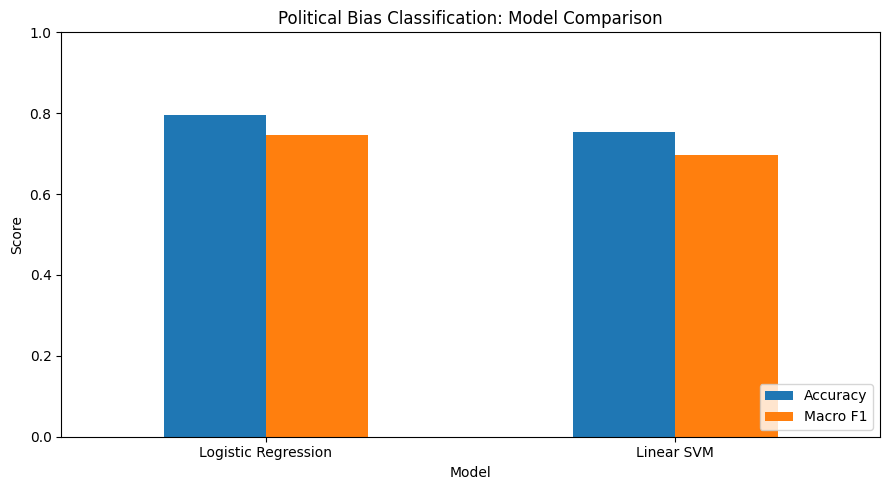

In [8]:
results_df.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("Political Bias Classification: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Evaluate the best model

Best model: Logistic Regression
Test accuracy: 79.48%
\nClassification report:
                    precision    recall  f1-score   support

  Democrat-leaning       0.85      0.87      0.86      1272
Republican-leaning       0.66      0.61      0.63       521

          accuracy                           0.79      1793
         macro avg       0.75      0.74      0.75      1793
      weighted avg       0.79      0.79      0.79      1793



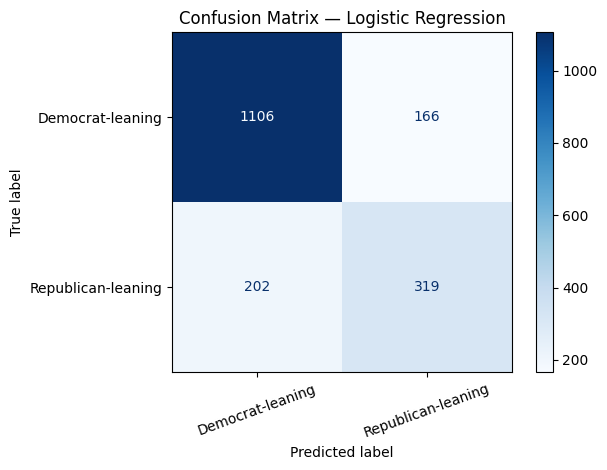

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Best model:", best_model_name)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", xticks_rotation=20
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 12. Save the trained model

In [24]:
Path("artifacts").mkdir(exist_ok=True)
model_path = Path("artifacts/political_bias_model.joblib")
joblib.dump(best_model, model_path)
print("Saved model to:", model_path.resolve())

Saved model to: C:\Projects\Mini_Proj\artifacts\political_bias_model.joblib


## 13. Predict a new article

In [28]:
loaded_model = joblib.load("artifacts/political_bias_model.joblib")

new_article = """
Donald trump is an terrible president.
"""

prediction = loaded_model.predict([clean_text(new_article)])[0]
print("Predicted orientation:", prediction)

if hasattr(loaded_model.named_steps["classifier"], "predict_proba"):
    probabilities = loaded_model.predict_proba([clean_text(new_article)])[0]
    for label, probability in zip(loaded_model.classes_, probabilities):
        print(f"{label}: {probability:.2%}")
else:
    print("Linear SVM does not provide calibrated probabilities by default.")

Predicted orientation: Democrat-leaning
Democrat-leaning: 76.92%
Republican-leaning: 23.08%
